# CODE 5.3: Why the Alarms Rang

> **Goal:** notebook 5.2 showed *when* each model raised its alarms. This notebook asks *why*: which signals made each alarm go off, what the compressor was doing at that moment, and what the false alarms have in common.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/time_split.csv` and `results/leaks.csv` (1.2), `results/signals_used.json` (4.1), `models/isolation_forest.joblib` (4.1), `models/lstm_autoencoder.pt` (4.2), `results/alarm_rules.json` (5.1), and `results/window_scores.parquet` and `results/test_results.csv` (5.2).
> - **Output:** `results/alarm_events.csv`: every alarm event of the test months, with what the compressor did and which signals made it (for notebook 5.4 and the dashboard). At the end you should see **ALL CHECKS PASSED**.
>
> Nothing here changes a rule, a limit or a result of notebook 5.2. This notebook only looks inside the alarms.

### Two Ways to Look Inside an Alarm

> - **LSTM autoencoder:** its error is the average of 12 errors, one per signal (notebook 4.2), and notebook 5.2 saved all 12 for every window. So every error can be split into its signals, like a restaurant bill split by who ordered what: "half of this error comes from `DV_pressure`".
> - **Isolation Forest:** its score comes from all 40 summary numbers at once, so it cannot be split by simply reading it off. **SHAP** does the split: it gives every summary number a part of the score, and the parts add up exactly to the score. It is the same bill-splitting idea, with a fair rule from game theory (the Shapley value) for numbers that only matter together.
>
> For both models, the parts are then gathered per signal (for example, the 4 summary numbers of `TP2` together), so the two models can be compared signal by signal.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `hashlib`: folders and file paths, the rules file, and fingerprints of files.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts.
> - `joblib`: loads the Isolation Forest of notebook 4.1.
> - `shap`: splits the score of the forest into one part per summary number (SHAP values).
> - `torch` (PyTorch): rebuilds the LSTM autoencoder of notebook 4.2, to show what it expected in two windows.
> - `tqdm`: shows a progress bar while SHAP splits about 47,000 scores.
>
> Importing `shap` may print a `TqdmWarning` that `IProgress` was not found. It only means that progress bars are shown as plain text, and it can be ignored.

In [1]:
import os
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import joblib
import shap
import torch
from tqdm import tqdm

c:\Users\Kelvin Jonathan\Downloads\predictive-maintenance-metropt\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Variables

#### Folder Paths

> The inputs from notebooks 1.2, 3.1, 4.1, 4.2, 5.1 and 5.2, and the file this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
LEAKS_FILE = os.path.join(RESULTS_DIR, "leaks.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
RULES_FILE = os.path.join(RESULTS_DIR, "alarm_rules.json")
SCORES_FILE = os.path.join(RESULTS_DIR, "window_scores.parquet")
SUMMARY_FILE = os.path.join(RESULTS_DIR, "test_results.csv")
EVENTS_FILE = os.path.join(RESULTS_DIR, "alarm_events.csv")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
FOREST_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
LSTM_FILE = os.path.join(MODELS_DIR, "lstm_autoencoder.pt")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `OIL_COLUMN`, `PUMP_COLUMN`, `TANK_COLUMN`, `DRYER_COLUMN`: signals with a special job: the oil temperature, the pumping signal (`DV_eletric`, 1 while the compressor pumps), the tank pressure (`Reservoirs`), and `DV_pressure`, the pressure at the air dryer.
> - `CYCLE_FEATURES`: the three summary numbers about the pump cycles (notebook 3.1). They use two signals at once (`DV_eletric` and `Reservoirs`), so they are gathered as their own group, *pump cycles*.
> - `WINDOW_STEPS`, `TICK_SECONDS`: a window has 360 ticks, one every 10 seconds (notebook 3.1).
> - `SHAP_CHUNK`: SHAP splits this many windows at a time, so the progress bar can move.
> - `TOP_SIGNALS`: how many signals every alarm event lists.
> - `PUMP_RUN_MINUTES`, `DRYER_UP_BAR`: the edges of the pump-run lengths in "Long Pump Runs and DV_pressure", and the pressure above which `DV_pressure` counts as up.
> - `BUSY_QUANTILE`: an event "pumped more than usual" when the pump ran a larger part of its hours than in 99% of the February windows.
> - `HOURS_BEFORE_WARNING`, `HOURS_AFTER_LEAK`: the time range of the chart "Leak 4 Up Close".
> - `MODEL_NAMES`, `ZONE_COLORS`, `SIGNAL_COLORS`, `KIND_ORDER`: names, colors and the order of the kinds of false alarms.
>
> The alarm rule and the limits are read from `alarm_rules.json`, as in notebook 5.2.

In [3]:
OIL_COLUMN = "Oil_temperature"
PUMP_COLUMN = "DV_eletric"
TANK_COLUMN = "Reservoirs"
DRYER_COLUMN = "DV_pressure"
CYCLE_FEATURES = ["pump_starts", "drop_bar_per_min", "rise_bar_per_min"]
WINDOW_STEPS = 360
TICK_SECONDS = 10

SHAP_CHUNK = 2048
TOP_SIGNALS = 3
PUMP_RUN_MINUTES = [0, 2, 5, 10, 30, np.inf]
DRYER_UP_BAR = 0.5
BUSY_QUANTILE = 0.99
HOURS_BEFORE_WARNING = 12
HOURS_AFTER_LEAK = 6

MODEL_NAMES = {"isolation_forest": "Isolation Forest", "lstm_autoencoder": "LSTM autoencoder"}
ZONE_COLORS = {"warning": "#EF9F27", "leak": "#E24B4A", "ignored": "#B4B2A9"}
SIGNAL_COLORS = ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]
KIND_ORDER = ["pump never rested", "tanks below 7 bar", "pumped more than usual", "frozen readings", "other"]

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Fingerprints (from 5.1)

> `file_fingerprint()` and `rules_fingerprint()` are copied unchanged from notebook 5.1.

In [5]:
def file_fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

In [6]:
def rules_fingerprint(rules):
    text = json.dumps({key: value for key, value in rules.items() if key != "fingerprint"}, sort_keys=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

### Score Windows with the Forest (from 4.1)

> `anomaly_score()` is copied unchanged from notebook 4.1.

In [7]:
def anomaly_score(model, features):
    return -model.score_samples(features)

### Alarms and Events (from 5.1)

> `alarm_windows()` and `find_events()` are copied unchanged from notebook 5.1.

In [8]:
def alarm_windows(scores, ends, limit, in_a_row, step_minutes):
    above = pd.Series(scores > limit)
    restart = ~above | pd.Series(ends.diff().to_numpy() != np.timedelta64(step_minutes, "m"))
    run = above.astype(int).groupby(restart.cumsum()).cumsum()
    return (run >= in_a_row).to_numpy()

In [9]:
def find_events(alarms, counted, ends, merge_gap_minutes):
    times = ends[alarms & counted].reset_index(drop=True)
    new_event = times.diff().isna() | (times.diff() > pd.Timedelta(minutes=merge_gap_minutes))
    events = times.groupby(new_event.cumsum()).agg(["min", "max", "size"])
    return events.rename(columns={"min": "first_alarm", "max": "last_alarm", "size": "alarms"}).reset_index(drop=True)

### Cut Many Windows at Once (from 4.2)

> `cut_windows()` is copied unchanged from notebook 4.2.

In [10]:
def cut_windows(grid_values, end_indices, window_steps, oil_index):
    ticks = end_indices[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    windows = grid_values[ticks]
    windows[:, :, oil_index] -= windows[:, :1, oil_index]
    return windows

### The LSTM Autoencoder (from 4.2)

> `LSTMAutoencoder` is copied unchanged from notebook 4.2, so the saved weights fit into it.

In [11]:
class LSTMAutoencoder(torch.nn.Module):
    def __init__(self, n_signals, memory_size):
        super().__init__()
        self.encoder = torch.nn.LSTM(input_size=n_signals, hidden_size=memory_size, batch_first=True)
        self.decoder = torch.nn.LSTM(input_size=memory_size, hidden_size=memory_size, batch_first=True)
        self.output = torch.nn.Linear(in_features=memory_size, out_features=n_signals)

    def forward(self, windows):
        _, (memory, _) = self.encoder(windows)
        note = memory[-1].unsqueeze(1).repeat(1, windows.shape[1], 1)
        redrawn, _ = self.decoder(note)
        return self.output(redrawn)

### Average Path Length

> In Isolation Forest, the score of a window comes from its **path length**: how many cuts a tree needs, on average over all trees, to separate the window from the others. `average_path_length()` is the yardstick from the Isolation Forest paper that turns a path length into a score:
>
> score = 2 ^ (− path length / c), where c = 2·(ln(n − 1) + 0.5772) − 2·(n − 1) / n, and n is the number of February windows per tree.
>
> scikit-learn uses the same formula inside `score_samples()`. A short path (cut away quickly) gives a high score: unusual.

In [12]:
def average_path_length(n):
    return 2 * (np.log(n - 1) + np.euler_gamma) - 2 * (n - 1) / n

### SHAP Values in Chunks

> `forest_shap()` asks SHAP for the split of every window, chunk by chunk, with a progress bar. For every window it returns 40 SHAP values, one per summary number.

In [13]:
def forest_shap(explainer, features, chunk_size, label):
    parts = [explainer.shap_values(features.iloc[start:start + chunk_size]) for start in tqdm(range(0, len(features), chunk_size), desc=label)]
    return np.vstack(parts)

### Gather the Parts per Signal

> `parts_per_signal()` adds up the parts that belong to the same signal: for example the 4 summary numbers of `TP2` (`TP2_mean`, `TP2_std`, `TP2_min`, `TP2_max`). `signal_of` says which signal every column belongs to.

In [14]:
def parts_per_signal(parts, signal_of, signal_order):
    return parts.T.groupby(parts.columns.map(signal_of)).sum().T.reindex(columns=signal_order)

### Share of Each Signal

> `shares_of()` takes the windows of one group, adds up the parts of every signal over all of them, and divides by the total. The result says which share of the group's error (LSTM) or push (forest) each signal makes. Big alarms weigh more than small ones, like a bill split over many tables.

In [15]:
def shares_of(parts, mask):
    total = parts[mask].sum()
    return total / total.sum()

### The Middle Window of a Group

> `middle_window()` picks the window in the middle of a group: the one with the median value. The charts use it, so every example hour is a typical hour of its group, not a hand-picked one.

In [16]:
def middle_window(values, mask):
    positions = np.flatnonzero(mask)
    order = positions[np.argsort(values[positions], kind="stable")]
    return int(order[len(order) // 2])

### Describe Each Event

> `describe_events()` takes the alarm events of one model and describes each of them with its alarm windows:
>
> - when it started and ended, and how many alarm windows it has, how many of them frozen (notebook 5.2);
> - in how many of its windows the pump never rested (`drop_bar_per_min` = 0, as in notebooks 3.2 and 5.2), what share of the hour the pump ran (median), and the lowest tank pressure;
> - whether `LPS` switched on in any of its windows: the tanks fell below 7 bar;
> - the signals with the largest shares (`shares_of()`), and what the event **looks like**, with the first rule that fits:
>
> 1. **frozen readings:** at least half of its alarm windows are frozen;
> 2. **pump never rested:** in at least half of its alarm windows the pump never rested;
> 3. **tanks below 7 bar:** `LPS` was on in at least one of its windows;
> 4. **pumped more than usual:** the middle value of its pump share (over its alarm windows) is above `busy_limit`;
> 5. **other:** none of the above.
>
> The order matters: a frozen window also looks like a pump that never rested, because nothing moves.

In [17]:
def describe_events(events, alarms, counted, df_test, parts, busy_limit, top_signals, pump_column, tank_column):
    rows = []
    for event in events.itertuples():
        inside = alarms & counted & (df_test["end"] >= event.first_alarm).to_numpy() & (df_test["end"] <= event.last_alarm).to_numpy()
        part = df_test[inside]
        frozen_share = part["frozen"].mean()
        never_rested = (part["drop_bar_per_min"] == 0).mean()
        low_tanks = bool((part["LPS_on_share"] > 0).any())
        pumping = part[f"{pump_column}_on_share"].median()
        looks_like = ("frozen readings" if frozen_share >= 0.5 else "pump never rested" if never_rested >= 0.5
                      else "tanks below 7 bar" if low_tanks else "pumped more than usual" if pumping > busy_limit else "other")
        top = shares_of(parts=parts, mask=inside).sort_values(ascending=False).head(top_signals)
        rows.append({"first_alarm": event.first_alarm, "last_alarm": event.last_alarm, "alarm_windows": int(inside.sum()),
                     "frozen_windows": int(part["frozen"].sum()), "pump_never_rested": never_rested, "pumping_share": pumping,
                     "lowest_tank_bar": part[f"{tank_column}_min"].min(), "tanks_below_7_bar": low_tanks, "looks_like": looks_like,
                     "top_signals": ", ".join(f"{signal} {share:.0%}" for signal, share in top.items())})
    return pd.DataFrame(rows)

### Draw a Heatmap

> `draw_heatmap()` draws a table of shares as colored cells: one row per group, one column per signal, darker for a larger share. The number in every cell is the share.

In [18]:
def draw_heatmap(shares, labels, title, cmap):
    fig, ax = plt.subplots(figsize=(0.8 * shares.shape[1] + 4.6, 0.42 * shares.shape[0] + 1.9))
    image = ax.imshow(shares.to_numpy(dtype=float), cmap=cmap, vmin=0, vmax=shares.to_numpy(dtype=float).max(), aspect="auto")
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            value = shares.iat[i, j]
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=8.5, color="white" if image.norm(value) > 0.55 else "#1F1F1E")
    ax.set_xticks(range(shares.shape[1]), labels=shares.columns, rotation=35, ha="right", fontsize=9)
    ax.set_yticks(range(shares.shape[0]), labels=labels, fontsize=9)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()

### Hours in Real Units

> `hours_in_real_units()` takes the 360 ticks of some windows from the grid of notebook 3.1, for the chosen signals, and undoes the scaling of notebook 3.1 for the analog signals, so pressures are in bar again. It returns one table per signal: one row per window, one column per tick.

In [19]:
def hours_in_real_units(grid_values, grid_signals, scaled_columns, scale_mean, scale_std, end_indices, window_steps, columns):
    ticks = np.asarray(end_indices)[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    hours = {}
    for column in columns:
        values = grid_values[ticks, grid_signals.index(column)].astype("float64")
        if column in scaled_columns:
            values = values * scale_std[scaled_columns.index(column)] + scale_mean[scaled_columns.index(column)]
        hours[column] = values
    return hours

### Draw Example Hours

> `draw_hours()` draws one row per example hour: on the left the tank pressure, on the right `DV_pressure`. The orange background marks the minutes in which the pump ran (`DV_eletric` = 1).

In [20]:
def draw_hours(titles, hours, pump_column, tank_column, dryer_column, minutes, pump_color):
    fig, axes = plt.subplots(len(titles), 2, figsize=(14, 2.25 * len(titles)), sharex=True, squeeze=False)
    for row, title in enumerate(titles):
        for col, (values, name, color, low, high) in enumerate([(hours[tank_column][row], "tank pressure (bar)", "#1F1F1E", 0, 11),
                                                                (hours[dryer_column][row], "DV_pressure (bar)", "#534AB7", -0.5, 6.5)]):
            ax = axes[row, col]
            ax.fill_between(minutes, 0, 1, where=hours[pump_column][row] > 0.5, color=pump_color, alpha=0.3, linewidth=0, transform=ax.get_xaxis_transform(), label="pump on")
            ax.plot(minutes, values, color=color, linewidth=1.3)
            ax.set_ylim(low, high)
            ax.set_title(f"{title}: {name}", fontsize=9.5, loc="left")
            for side in ["top", "right"]:
                ax.spines[side].set_visible(False)
    for col in range(2):
        axes[-1, col].set_xlabel("minutes into the window")
    axes[0, 0].legend(loc="lower right", frameon=False, fontsize=8.5)
    plt.tight_layout()
    plt.show()

## Load Everything

### Read the Files

> The windows with their summary numbers (3.1), the scores, errors and alarms of every window (5.2), and the grid of readings (3.1) for the example hours. The rules file must still match its fingerprint.

In [21]:
with np.load(GRID_FILE) as saved:
    grid_values, grid_signals = saved["values"], saved["signals"].tolist()
    scaled_columns, scale_mean, scale_std = saved["scaled_columns"].tolist(), saved["scale_mean"], saved["scale_std"]
    has_reading, tick_seconds = saved["has_reading"], saved["tick_seconds"]
df_windows = pd.read_parquet(WINDOWS_FILE)
df_scores = pd.read_parquet(SCORES_FILE)
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
leaks = pd.read_csv(LEAKS_FILE, parse_dates=["warning_from", "start", "end", "ignored_until"], keep_default_na=False)
summary_5_2 = pd.read_csv(SUMMARY_FILE, index_col="model")
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_info = json.load(f)
with open(RULES_FILE, encoding="utf-8") as f:
    rules = json.load(f)

SIGNALS = signals_info["signals"]
FEATURE_COLUMNS = signals_info["isolation_forest_features"]
IN_A_ROW, STEP_MINUTES = rules["alarm_rule"]["in_a_row"], rules["alarm_rule"]["window_step_minutes"]
MERGE_GAP_MINUTES = rules["alarm_rule"]["merge_gap_minutes"]
LIMITS = {model: rules["limits"][model]["main"] for model in MODEL_NAMES}

print(f"Windows: {len(df_windows):,} | rows in window_scores.parquet: {len(df_scores):,} | grid ticks: {len(grid_values):,}")
print("Locked main limits:", {MODEL_NAMES[model]: round(limit, 4) for model, limit in LIMITS.items()})
check("the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)", rules_fingerprint(rules=rules) == rules["fingerprint"])

Windows: 47,491 | rows in window_scores.parquet: 47,491 | grid ticks: 1,841,760
Locked main limits: {'Isolation Forest': 0.7326, 'LSTM autoencoder': 0.78}
PASS  the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)


### Load the Two Models and Compare Their Fingerprints

> As in notebook 5.2: the two model files must be exactly the ones the limits were set for.

In [22]:
forest = joblib.load(FOREST_FILE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
saved_lstm = torch.load(LSTM_FILE, map_location=device, weights_only=True)
lstm = LSTMAutoencoder(n_signals=len(saved_lstm["signals"]), memory_size=saved_lstm["memory_size"]).to(device)
lstm.load_state_dict(saved_lstm["state_dict"])
lstm.eval()
fingerprints = {os.path.basename(path): file_fingerprint(path=path) for path in [FOREST_FILE, LSTM_FILE]}

for name, value in fingerprints.items():
    print(f"{name}: {value[:16]}... | saved by notebook 5.1: {rules['model_files'][name][:16]}...")
print("LSTM runs on:", device.type)
check("the two model files are exactly the ones the limits were set for (their fingerprints match)", fingerprints == rules["model_files"])

isolation_forest.joblib: 5097501b4dda5e40... | saved by notebook 5.1: 5097501b4dda5e40...
lstm_autoencoder.pt: 84626161ecb960ac... | saved by notebook 5.1: 84626161ecb960ac...
LSTM runs on: cuda
PASS  the two model files are exactly the ones the limits were set for (their fingerprints match)


### Are the Saved Scores Still the Right Ones?

> This notebook explains the alarms that notebook 5.2 saved, so they must still belong to these models and these limits. Four checks:
>
> 1. `window_scores.parquet` has one row for every window of `windows.parquet`, in the same order.
> 2. The forest gives every window exactly the score saved by notebook 5.2.
> 3. The alarm rule with the locked limits gives exactly the saved alarms, in every part (February, March, the test months).
> 4. The alarms in healthy test time form as many false alarm events as notebook 5.2 counted.

In [23]:
same_windows = len(df_scores) == len(df_windows) and np.array_equal(df_scores["end"].to_numpy(), df_windows["end"].to_numpy())
check("window_scores.parquet has one row for every window, in the same order", same_windows)

forest_scores = anomaly_score(model=forest, features=df_windows[FEATURE_COLUMNS])
print(f"Largest difference between the forest scores now and in window_scores.parquet: {np.abs(forest_scores - df_scores['isolation_forest'].to_numpy()).max():.1e}")
check("the forest scores every window exactly as notebook 5.2 saved", np.allclose(forest_scores, df_scores["isolation_forest"].to_numpy(), rtol=0, atol=1e-12))

same_alarms = True
for model in MODEL_NAMES:
    for split in df_scores["split"].unique():
        mask = (df_scores["split"] == split).to_numpy()
        again = alarm_windows(scores=df_scores.loc[mask, model].to_numpy(), ends=df_scores.loc[mask, "end"].reset_index(drop=True),
                              limit=LIMITS[model], in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES)
        same_alarms = same_alarms and np.array_equal(again, df_scores.loc[mask, f"{model}_alarm"].to_numpy())
check("the saved alarms are exactly what the locked limits give", same_alarms)

PASS  window_scores.parquet has one row for every window, in the same order
Largest difference between the forest scores now and in window_scores.parquet: 0.0e+00
PASS  the forest scores every window exactly as notebook 5.2 saved
PASS  the saved alarms are exactly what the locked limits give


In [24]:
df_all = pd.concat([df_scores, df_windows.drop(columns=["end", "split"])], axis=1)
is_test = (df_all["split"] == "test").to_numpy()
df_test = df_all[is_test].reset_index(drop=True)
healthy = (df_test["zone"] == "healthy").to_numpy()
false_events = {model: find_events(alarms=df_test[f"{model}_alarm"].to_numpy(), counted=healthy, ends=df_test["end"], merge_gap_minutes=MERGE_GAP_MINUTES)
                for model in MODEL_NAMES}

for model, name in MODEL_NAMES.items():
    print(f"{name}: false alarm events {len(false_events[model])} | notebook 5.2: {summary_5_2.loc[name, 'false alarm events']}")
check("the false alarm events are the same as in notebook 5.2", all(len(false_events[model]) == summary_5_2.loc[name, "false alarm events"] for model, name in MODEL_NAMES.items()))

Isolation Forest: false alarm events 8 | notebook 5.2: 8
LSTM autoencoder: false alarm events 21 | notebook 5.2: 21
PASS  the false alarm events are the same as in notebook 5.2


## The LSTM: Which Signal Made the Error?

### The Error of Every Signal

> Notebook 4.2 measured the error of a window as the average of 12 errors, one per signal. Divided by 12, these become 12 **parts** that add up exactly to the error of the window. The check makes sure the saved errors still add up.
>
> The table shows the normal level: the middle error of every signal in February, and the share of every signal in all February errors together. Some signals are always harder to redraw than others, even in a healthy hour.

In [25]:
error_columns = [f"lstm_error_{signal}" for signal in SIGNALS]
lstm_parts = df_all[error_columns].rename(columns=lambda column: column.replace("lstm_error_", "")) / len(SIGNALS)
gap = np.abs(lstm_parts.sum(axis=1).to_numpy() - df_all["lstm_autoencoder"].to_numpy())
print(f"Largest difference between an error and the sum of its 12 parts: {gap.max():.1e}")
check("the error of every window is the sum of its 12 signal parts", np.allclose(lstm_parts.sum(axis=1), df_all["lstm_autoencoder"], rtol=1e-5, atol=1e-6))

is_february = (df_all["split"] == "train").to_numpy()
normal_level = pd.DataFrame({"middle error in February": df_all.loc[is_february, error_columns].median().to_numpy(),
                             "share of all February errors": shares_of(parts=lstm_parts, mask=is_february).to_numpy()}, index=SIGNALS)
display(normal_level.sort_values("share of all February errors", ascending=False).style.format({"middle error in February": "{:.3f}", "share of all February errors": "{:.0%}"}))

Largest difference between an error and the sum of its 12 parts: 1.2e-06
PASS  the error of every window is the sum of its 12 signal parts


,middle error in February,share of all February errors
Reservoirs,0.177,20%
TP3,0.176,20%
Oil_temperature,0.154,15%
Motor_current,0.072,12%
H1,0.097,12%
TP2,0.068,8%
DV_pressure,0.023,4%
Towers,0.033,3%
MPG,0.016,2%
COMP,0.016,2%


> **What we see:** even in February the error is not spread evenly. The tank pressures (`TP3`, `Reservoirs`) and the oil temperature carry the largest shares of the normal error, the on/off signals the smallest. So a signal with a large share is not unusual by itself: the share must be compared with this normal level.

### The Groups of Windows

> To compare like with like, the windows are put into groups:
>
> - **February:** all training windows, the normal level.
> - **Test months, healthy, no alarm:** healthy test windows in which neither model raised an alarm.
> - **Warning zone of leak 1 to 4:** the 24 hours before each leak.
> - **During leak 1 to 4.**
> - **False alarms of each model:** its alarm windows in healthy test time.
>
> Frozen windows (notebook 5.2) are left out of every group: in them nothing moves, so they say nothing about how the compressor worked. The section "Every False Alarm" looks at them separately.

In [26]:
real = ~df_all["frozen"].to_numpy()
zone, leak_number = df_all["zone"].to_numpy(), df_all["leak"].to_numpy()
any_alarm = df_all["isolation_forest_alarm"].to_numpy() | df_all["lstm_autoencoder_alarm"].to_numpy()
groups = {"February": is_february, "Test months, healthy, no alarm": is_test & (zone == "healthy") & ~any_alarm & real}
for number in leaks["leak"]:
    groups[f"Warning zone of leak {number}"] = is_test & (zone == "warning") & (leak_number == number) & real
for number in leaks["leak"]:
    groups[f"During leak {number}"] = is_test & (zone == "leak") & (leak_number == number) & real
for model, name in MODEL_NAMES.items():
    groups[f"False alarms, {name}"] = is_test & (zone == "healthy") & df_all[f"{model}_alarm"].to_numpy() & real

display(pd.DataFrame({"windows": {group: int(mask.sum()) for group, mask in groups.items()}}))

,windows
February,6790
"Test months, healthy, no alarm",27569
Warning zone of leak 1,64
Warning zone of leak 2,226
Warning zone of leak 3,288
Warning zone of leak 4,192
During leak 1,271
During leak 2,79
During leak 3,549
During leak 4,43


### Which Signals Make the Error, Group by Group

> For every group, the share of each signal in the group's error. Every row adds up to 100%. The number after the group name is the middle error of the group; the locked limit of the LSTM is printed above the chart.

Locked limit of the LSTM autoencoder: 0.7800


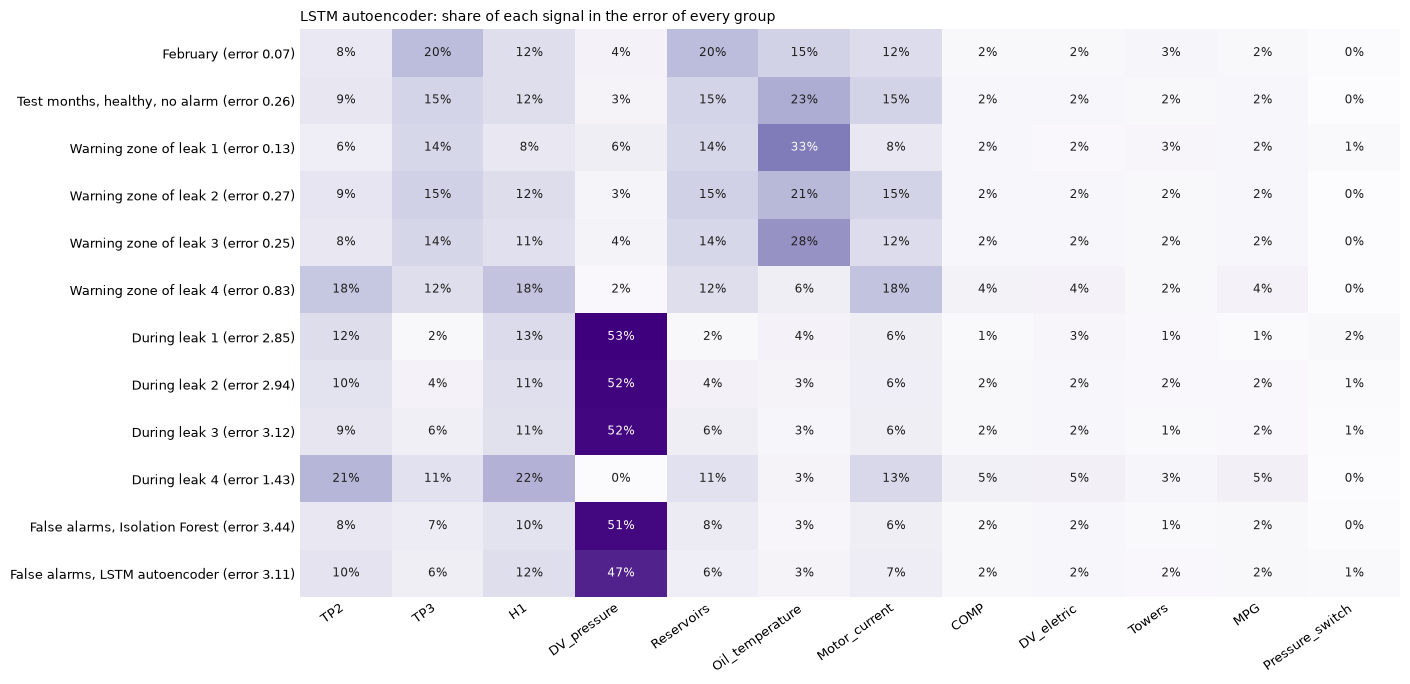

In [27]:
lstm_shares = pd.DataFrame({group: shares_of(parts=lstm_parts, mask=mask) for group, mask in groups.items()}).T
labels = [f"{group} (error {df_all.loc[mask, 'lstm_autoencoder'].median():.2f})" for group, mask in groups.items()]
print(f"Locked limit of the LSTM autoencoder: {LIMITS['lstm_autoencoder']:.4f}")
draw_heatmap(shares=lstm_shares, labels=labels, title="LSTM autoencoder: share of each signal in the error of every group", cmap="Purples")

> **What we see:**
>
> - **During leaks 1, 2 and 3**, about half of the whole error comes from one signal, `DV_pressure`, which carries almost nothing in February. Much of the rest comes from `H1`, `TP2` and `Motor_current`, the signals that follow the pump: they jump when the pump starts or stops.
> - **During leak 4** and **in its warning zone**, `DV_pressure` carries almost nothing. There the pump signals (`H1`, `TP2`, `Motor_current`) carry the error, together with the tank pressures.
> - **The warning zones of leaks 1, 2 and 3** look like the healthy test hours: small errors, with the oil temperature as the largest share.
> - **The false alarms of both models** look like the first three leaks: `DV_pressure` again carries about half of the error.
>
> The section "What the Compressor Did" shows what these signals did.

## The Forest: Which Summary Number Pushed the Score?

### How SHAP Splits a Score

> For the forest, SHAP splits the **path length** of a window, not the score itself, because the path length is what the trees measure:
>
> - The **starting point** is the average path length of the February windows (SHAP calls it the expected value).
> - Every summary number gets a SHAP value: how much it changed the path length of this window, compared with that starting point. The 40 values add up exactly to the difference.
> - We flip the sign and call it a **push**: a positive push made the window easier to cut away, so it pushed the score up (more unusual). A negative push made the window look more normal.
>
> So: path length of a window = starting point − sum of its 40 pushes, and the score follows from the path length with `average_path_length()`. The check makes sure this gives back every score of the forest exactly.

In [28]:
explainer = shap.TreeExplainer(forest)
shap_values = forest_shap(explainer=explainer, features=df_windows[FEATURE_COLUMNS], chunk_size=SHAP_CHUNK, label="SHAP values, all windows")
start_path = float(np.ravel(explainer.expected_value)[0])
pushes = pd.DataFrame(-shap_values, columns=FEATURE_COLUMNS)
c = average_path_length(n=forest.max_samples_)
paths = start_path - pushes.sum(axis=1).to_numpy()

print(f"Starting point (average path length in February): {start_path:.3f} cuts | c for {forest.max_samples_} windows per tree: {c:.3f}")
print(f"Largest difference between the score from SHAP and the score of the forest: {np.abs(2 ** (-paths / c) - df_all['isolation_forest'].to_numpy()).max():.1e}")
check("SHAP adds up: the 40 pushes of every window give back its score", np.allclose(2 ** (-paths / c), df_all["isolation_forest"].to_numpy(), rtol=0, atol=1e-9))

SHAP values, all windows: 100%|██████████| 24/24 [02:56<00:00,  7.34s/it]

Starting point (average path length in February): 12.508 cuts | c for 256 windows per tree: 10.245
Largest difference between the score from SHAP and the score of the forest: 5.6e-16
PASS  SHAP adds up: the 40 pushes of every window give back its score


### The Push the Limit Needs

> The locked limit of the forest can be turned into a push: a window is above the limit only if its 40 pushes together are larger than this (and an alarm needs 3 such windows in a row). The table shows, for every group, the middle total push, the largest one, and how many of its windows are above the limit.

In [29]:
needed_push = start_path + c * np.log2(LIMITS["isolation_forest"])
total_push = pushes.sum(axis=1).to_numpy()
push_table = pd.DataFrame({"middle total push": {group: np.median(total_push[mask]) for group, mask in groups.items()},
                           "largest total push": {group: total_push[mask].max() for group, mask in groups.items()},
                           "windows above the limit": {group: (total_push[mask] > needed_push).mean() for group, mask in groups.items()}})
print(f"Locked limit {LIMITS['isolation_forest']:.4f} = a total push of {needed_push:.2f} | largest total push of any window: {total_push.max():.2f}")
display(push_table.style.format({"middle total push": "{:.2f}", "largest total push": "{:.2f}", "windows above the limit": "{:.0%}"}))

Locked limit 0.7326 = a total push of 7.91 | largest total push of any window: 8.40


,middle total push,largest total push,windows above the limit
February,-0.13,7.96,0%
"Test months, healthy, no alarm",5.28,8.40,0%
Warning zone of leak 1,3.70,7.25,0%
Warning zone of leak 2,5.24,7.22,0%
Warning zone of leak 3,4.83,7.37,0%
Warning zone of leak 4,7.12,7.96,3%
During leak 1,7.46,7.60,0%
During leak 2,7.63,7.70,0%
During leak 3,7.65,8.14,12%
During leak 4,7.37,7.78,0%


> **What we see:** an average February hour has a total push of about zero, by definition: it is the starting point. The healthy test hours are already pushed a good way up, like March in notebook 4.1. The warning zone of leak 4 is pushed almost as far as the leaks, the other warning zones much less. During the leaks the middle push stays just under the push the limit needs, and the largest push of any window is not much higher. This is the ceiling of notebook 4.1, now in pushes: once a window is clearly unusual, more unusual summary numbers cannot shorten its path much further.

### Which Signals Push, Group by Group

> As for the LSTM: the pushes are gathered per signal, plus the group *pump cycles*, and every row shows the share of each in the group's total push. February is left out here: its total push is about zero, so its shares would mean nothing.

Push the limit needs: 7.91


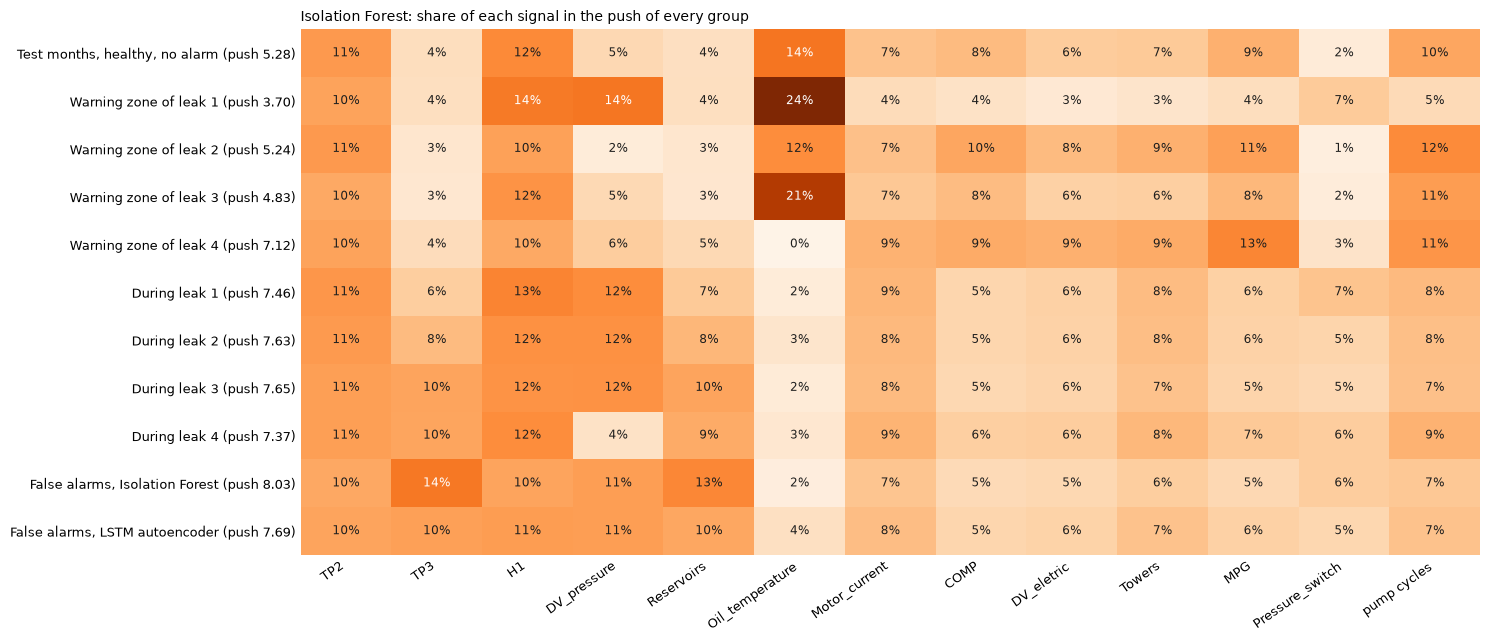

In [30]:
FEATURE_SIGNAL = {feature: "pump cycles" if feature in CYCLE_FEATURES else next(signal for signal in SIGNALS if feature.startswith(f"{signal}_")) for feature in FEATURE_COLUMNS}
forest_parts = parts_per_signal(parts=pushes, signal_of=FEATURE_SIGNAL, signal_order=SIGNALS + ["pump cycles"])
forest_groups = {group: mask for group, mask in groups.items() if group != "February"}
forest_shares = pd.DataFrame({group: shares_of(parts=forest_parts, mask=mask) for group, mask in forest_groups.items()}).T
labels = [f"{group} (push {np.median(total_push[mask]):.2f})" for group, mask in forest_groups.items()]
print(f"Push the limit needs: {needed_push:.2f}")
draw_heatmap(shares=forest_shares, labels=labels, title="Isolation Forest: share of each signal in the push of every group", cmap="Oranges")

> **What we see:** the forest spreads its push over many signals at once: no signal takes half, as `DV_pressure` does for the LSTM. During the leaks the pushes come from the pump signals and the pressures together. In the warning zone of leak 4, about half of the push comes from the pump: the on/off signals (`MPG`, `COMP`, `DV_eletric`), the dryer `Towers` and the pump cycles. In the forest's own false alarms, the tank pressures (`TP3`, `Reservoirs`) push the most. The next table shows the single summary numbers behind this.

### The Strongest Summary Numbers

> For three groups, the 5 summary numbers with the largest average push, with their middle value in the group and in February. The leaks are taken together here.

In [31]:
during_leaks = np.logical_or.reduce([mask for group, mask in groups.items() if group.startswith("During leak")])
focus = {"During the 4 leaks": during_leaks, "Warning zone of leak 4": groups["Warning zone of leak 4"], "False alarms, Isolation Forest": groups["False alarms, Isolation Forest"]}
rows = []
for group, mask in focus.items():
    for feature, push in pushes[mask].mean().sort_values(ascending=False).head(5).items():
        rows.append({"group": group, "summary number": feature, "average push": push,
                     "middle value in the group": df_all.loc[mask, feature].median(), "middle value in February": df_all.loc[is_february, feature].median()})
display(pd.DataFrame(rows).set_index(["group", "summary number"]).round(3))

average push  \
group                          summary number                      
During the 4 leaks             rise_bar_per_min            0.374   
                               DV_pressure_mean            0.333   
                               H1_max                      0.329   
                               MPG_on_share                0.313   
                               Towers_switches             0.297   
Warning zone of leak 4         MPG_switches                0.505   
                               MPG_on_share                0.413   
                               rise_bar_per_min            0.406   
                               COMP_on_share               0.373   
                               DV_eletric_on_share         0.360   
False alarms, Isolation Forest TP3_min                     0.517   
                               Reservoirs_min              0.427   
                               rise_bar_per_min            0.343   
                               DV_pressure_mean            0.328   
                               H1_max                      0.296   

                                                    middle value in the group  \
group                          summary number                                   
During the 4 leaks             rise_bar_per_min                        -0.000   
                               DV_pressure_mean                         1.948   
                               H1_max                                  -0.004   
                               MPG_on_share                             0.000   
                               Towers_switches                         61.000   
Warning zone of leak 4         MPG_switches                            14.000   
                               MPG_on_share                             0.621   
                               rise_bar_per_min                         0.703   
                               COMP_on_share                            0.621   
                               DV_eletric_on_share                      0.379   
False alarms, Isolation Forest TP3_min                                  7.462   
                               Reservoirs_min                           7.462   
                               rise_bar_per_min                        -0.000   
                               DV_pressure_mean                         2.300   
                               H1_max                                  -0.002   

                                                    middle value in February  
group                          summary number                                 
During the 4 leaks             rise_bar_per_min                        1.201  
                               DV_pressure_mean                       -0.017  
                               H1_max                                 10.100  
                               MPG_on_share                            0.939  
                               Towers_switches                         4.000  
Warning zone of leak 4         MPG_switches                            4.000  
                               MPG_on_share                            0.939  
                               rise_bar_per_min                        1.201  
                               COMP_on_share                           0.939  
                               DV_eletric_on_share                     0.061  
False alarms, Isolation Forest TP3_min                                 8.042  
                               Reservoirs_min                          8.046  
                               rise_bar_per_min                        1.201  
                               DV_pressure_mean                       -0.017  
                               H1_max                                 10.100

> **What we see:**
>
> - **During the leaks**, the strongest pushes come from how fast the tank pressure rises while pumping (`rise_bar_per_min`, about zero instead of more than 1 bar per minute), from `DV_pressure`, from the pump signals (`H1_max`, the on-share of `MPG`), and from the dryer towers, which switched many times more often than in February (`Towers_switches`): the pump ran all the time and the pressure did not rise.
> - **In the warning zone of leak 4**, the pump switched on and off much more often than in February (`MPG_switches`), ran a larger part of the hour, and the pressure rose more slowly while it pumped.
> - **In the false alarms of the forest**, the lowest tank pressures (`TP3_min`, `Reservoirs_min`) are the strongest pushes: these hours had lower tank pressures than a normal February hour.

## What the Compressor Did

### Pump Behavior in Every Group

> The same groups, now with summary numbers you can picture (notebook 3.1):
>
> - **pump never rested:** share of the windows in which the pump did not rest once in the hour;
> - **pump starts per hour**, and the **share of the hour pumping** (`DV_eletric` on);
> - **pressure drop while resting** and **pressure rise while pumping**, in bar per minute;
> - **lowest tank pressure** in the hour, and the **average DV_pressure**.
>
> Every number except the first is the middle value (median) of the group.

In [32]:
behavior = pd.DataFrame({group: {"windows": int(mask.sum()),
                                 "pump never rested": (df_all.loc[mask, "drop_bar_per_min"] == 0).mean(),
                                 "pump starts per hour": df_all.loc[mask, "pump_starts"].median(),
                                 "share of the hour pumping": df_all.loc[mask, f"{PUMP_COLUMN}_on_share"].median(),
                                 "pressure drop while resting (bar/min)": df_all.loc[mask, "drop_bar_per_min"].median(),
                                 "pressure rise while pumping (bar/min)": df_all.loc[mask, "rise_bar_per_min"].median(),
                                 "lowest tank pressure (bar)": df_all.loc[mask, f"{TANK_COLUMN}_min"].median(),
                                 "average DV_pressure (bar)": df_all.loc[mask, f"{DRYER_COLUMN}_mean"].median()}
                         for group, mask in groups.items()}).T
display(behavior.style.format({"windows": "{:,.0f}", "pump never rested": "{:.0%}", "pump starts per hour": "{:.0f}", "share of the hour pumping": "{:.0%}",
                               "pressure drop while resting (bar/min)": "{:.2f}", "pressure rise while pumping (bar/min)": "{:.2f}",
                               "lowest tank pressure (bar)": "{:.1f}", "average DV_pressure (bar)": "{:.2f}"}))

,windows,pump never rested,pump starts per hour,share of the hour pumping,pressure drop while resting (bar/min),pressure rise while pumping (bar/min),lowest tank pressure (bar),average DV_pressure (bar)
February,"6,790",0%,2,6%,0.07,1.20,8.0,-0.02
"Test months, healthy, no alarm","27,569",0%,3,11%,0.11,0.93,8.1,-0.02
Warning zone of leak 1,64,0%,2,7%,0.07,1.06,8.1,-0.02
Warning zone of leak 2,226,0%,3,12%,0.12,0.88,8.0,-0.02
Warning zone of leak 3,288,0%,3,11%,0.10,0.92,8.0,-0.02
Warning zone of leak 4,192,0%,7,38%,0.39,0.70,8.0,-0.00
During leak 1,271,100%,0,100%,0.00,-0.00,8.7,1.90
During leak 2,79,87%,0,100%,0.00,-0.00,8.3,1.95
During leak 3,549,98%,0,100%,0.00,-0.00,7.9,2.08
During leak 4,43,67%,0,100%,0.00,-0.01,8.0,-0.01


> **What we see:**
>
> - **During leaks 1, 2 and 3** the compressor pumped the whole hour in almost every window, the tank pressure did not rise any more, and `DV_pressure` sat clearly above zero, where February keeps it. **During leak 4** the pump also ran nonstop in most windows, but `DV_pressure` stayed at zero. That is why the LSTM error of leak 4 comes from other signals.
> - **The warning zones of leaks 1, 2 and 3** look like healthy test hours: nothing in these numbers announced those leaks.
> - **The warning zone of leak 4 is different.** The pump still rested, but the tank pressure dropped several times faster while resting, so the pump had to start much more often and ran a much larger part of the hour. This is the slow puncture of the README: air escaping while the compressor rests.
> - **The false alarms** of both models look much more like the leaks than like healthy hours: long pumping, and `DV_pressure` above zero.

### Long Pump Runs and DV_pressure

> `DV_pressure` carries the largest share of the LSTM error during leaks 1 to 3. To see when it moves, every pump run of the grid (the pump on without a break) is sorted by how long it lasted. For every length and every part of the data, the table shows how many pump runs there were, and in which share of them `DV_pressure` was up (its middle value in the run above `DRYER_UP_BAR`).

In [33]:
pump_on = (grid_values[:, grid_signals.index(PUMP_COLUMN)] > 0.5) & has_reading
dryer_bar = grid_values[:, grid_signals.index(DRYER_COLUMN)] * scale_std[scaled_columns.index(DRYER_COLUMN)] + scale_mean[scaled_columns.index(DRYER_COLUMN)]
tick_time = pd.to_datetime(tick_seconds, unit="s")
part = np.select([tick_time < pd.Timestamp(split_table.loc["validation", "from"]), tick_time < pd.Timestamp(split_table.loc["test", "from"])],
                 ["February", "March"], default="April to August")
df_runs = (pd.DataFrame({"run": np.cumsum(~pump_on), "part": part, "DV_pressure": dryer_bar})[pump_on]
           .groupby("run").agg(part=("part", "first"), ticks=("DV_pressure", "size"), DV_pressure=("DV_pressure", "median")))
run_labels = [f"up to {high:g} min" if low == 0 else f"{low:g} to {high:g} min" if np.isfinite(high) else f"over {low:g} min" for low, high in zip(PUMP_RUN_MINUTES[:-1], PUMP_RUN_MINUTES[1:])]
df_runs["length"] = pd.cut(df_runs["ticks"] * TICK_SECONDS / 60, bins=PUMP_RUN_MINUTES, labels=run_labels)
run_table = df_runs.groupby(["length", "part"], observed=False).agg(runs=("ticks", "size"), DV_pressure_up=("DV_pressure", lambda values: (values > DRYER_UP_BAR).mean()))
part_order = ["February", "March", "April to August"]
shown = pd.concat({name: run_table.xs(name, level="part") for name in part_order}, axis=1)
display(shown.style.format({**{(name, "runs"): "{:,.0f}" for name in part_order}, **{(name, "DV_pressure_up"): "{:.0%}" for name in part_order}}, na_rep="-"))

> **What we see:** in February every pump run was short, and `DV_pressure` stayed at zero in all of them. Long pump runs only came in March and in the test months, and in many of them `DV_pressure` was up for most of the run (not in all of them: during leak 4 it stayed at zero). The LSTM never saw `DV_pressure` up in February, so it redraws a flat zero there, and the gap becomes a large error. During leaks 1 to 3 the pump ran for hours with `DV_pressure` up, so `DV_pressure` is the loudest signal of these leaks for the LSTM.

### Three Hours Up Close

> Three typical hours, each the middle window of its group by LSTM error: a February hour, an hour during leak 3, and an hour in the warning zone of leak 4.

February: window ending 23 Feb 10:20 | LSTM error 0.074 | forest score 0.389
During leak 3: window ending 06 Jun 03:55 | LSTM error 3.123 | forest score 0.711
Warning zone of leak 4: window ending 15 Jul 08:25 | LSTM error 0.827 | forest score 0.707


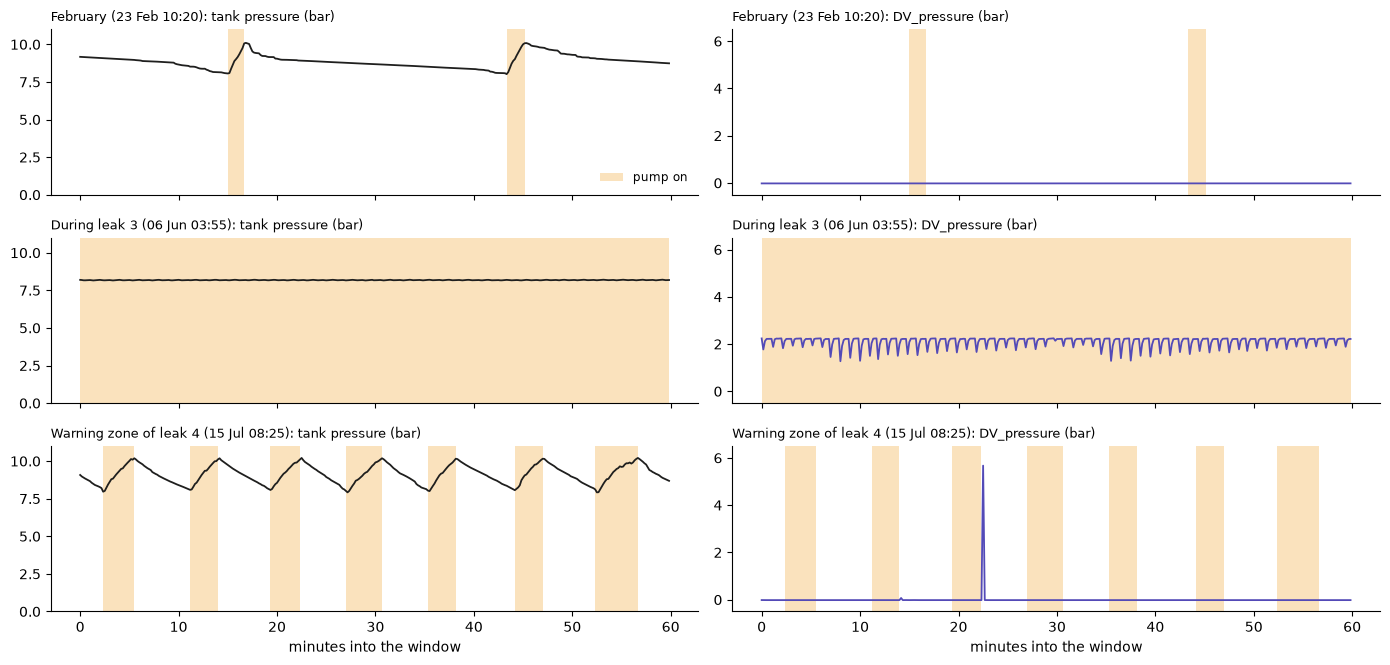

In [34]:
examples = {"February": middle_window(values=df_all["lstm_autoencoder"].to_numpy(), mask=groups["February"]),
            "During leak 3": middle_window(values=df_all["lstm_autoencoder"].to_numpy(), mask=groups["During leak 3"]),
            "Warning zone of leak 4": middle_window(values=df_all["lstm_autoencoder"].to_numpy(), mask=groups["Warning zone of leak 4"])}
minutes = np.arange(WINDOW_STEPS) * TICK_SECONDS / 60
for title, position in examples.items():
    print(f"{title}: window ending {df_all.loc[position, 'end']:%d %b %H:%M} | LSTM error {df_all.loc[position, 'lstm_autoencoder']:.3f} | forest score {df_all.loc[position, 'isolation_forest']:.3f}")
hours = hours_in_real_units(grid_values=grid_values, grid_signals=grid_signals, scaled_columns=scaled_columns, scale_mean=scale_mean, scale_std=scale_std,
                            end_indices=df_all.loc[list(examples.values()), "end_index"].to_numpy(), window_steps=WINDOW_STEPS, columns=[TANK_COLUMN, PUMP_COLUMN, DRYER_COLUMN])
draw_hours(titles=[f"{title} ({df_all.loc[position, 'end']:%d %b %H:%M})" for title, position in examples.items()], hours=hours,
           pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN, dryer_column=DRYER_COLUMN, minutes=minutes, pump_color=ZONE_COLORS["warning"])

> **What we see:**
>
> - **February:** the saw-tooth of notebook 2.1. The tank pressure falls slowly while the pump rests, a short pump run fills it up again, and `DV_pressure` stays at zero.
> - **During leak 3:** no saw-tooth at all. The pump runs the whole hour, the tank pressure stays flat below the level at which the pump would stop, and `DV_pressure` sits well above zero.
> - **Warning zone of leak 4:** still a saw-tooth, but a fast one. The pressure falls several times faster after every pump run, so the pump starts again and again. `DV_pressure` stays at zero most of the time.

### What the LSTM Expected

> The LSTM redraws the two unusual hours above. For each hour, the 4 signals with the largest share of its error, in the scaled units of notebook 3.1: the real values (dark) and the redrawn values (purple), as in notebook 4.2.

During leak 3: error saved by notebook 5.2 3.123 | error of this redraw 3.123
Warning zone of leak 4: error saved by notebook 5.2 0.827 | error of this redraw 0.827


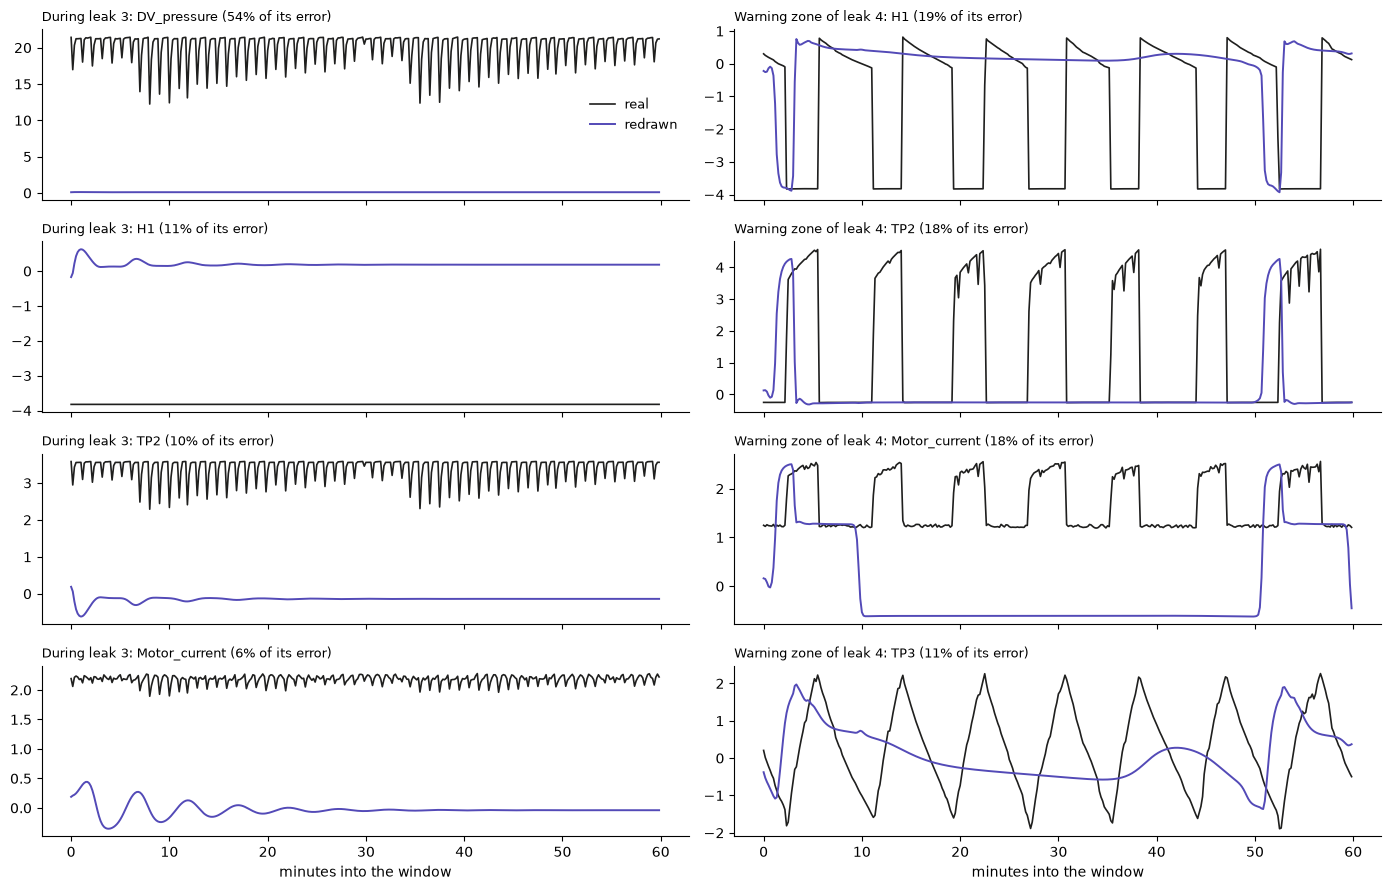

In [35]:
signal_columns = [grid_signals.index(signal) for signal in SIGNALS]
redraw_examples = {title: position for title, position in examples.items() if title != "February"}
fig, axes = plt.subplots(4, len(redraw_examples), figsize=(14, 9), sharex=True)
for col, (title, position) in enumerate(redraw_examples.items()):
    window = cut_windows(grid_values=grid_values, end_indices=np.array([df_all.loc[position, "end_index"]]), window_steps=WINDOW_STEPS, oil_index=grid_signals.index(OIL_COLUMN))[:, :, signal_columns]
    with torch.no_grad():
        redrawn = lstm(torch.from_numpy(np.ascontiguousarray(window)).to(device))[0].cpu().numpy()
    print(f"{title}: error saved by notebook 5.2 {df_all.loc[position, 'lstm_autoencoder']:.3f} | error of this redraw {np.abs(redrawn - window[0]).mean():.3f}")
    top = (lstm_parts.loc[position] / lstm_parts.loc[position].sum()).sort_values(ascending=False).head(4)
    for row, signal in enumerate(top.index):
        ax = axes[row, col]
        ax.plot(minutes, window[0, :, SIGNALS.index(signal)], color="#1F1F1E", linewidth=1.2, label="real")
        ax.plot(minutes, redrawn[:, SIGNALS.index(signal)], color="#534AB7", linewidth=1.4, label="redrawn")
        ax.set_title(f"{title}: {signal} ({top[signal]:.0%} of its error)", fontsize=9.5, loc="left")
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[-1, col].set_xlabel("minutes into the window")
axes[0, 0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

> **What we see:** in both hours the LSTM draws what a February hour would look like. During leak 3 it draws `DV_pressure` near zero while the real line sits far above it, and it draws `H1`, `TP2` and `Motor_current` as if the pump were resting, while the real pump ran the whole hour. In the warning zone of leak 4 the real pump runs come many times in the hour, the redrawn ones only once or twice, so the redrawn lines are off at many minutes. The gap between the dark and the purple lines is the error.

## Leak 4: the Early Warning

### Leak 4 Up Close

> From `HOURS_BEFORE_WARNING` hours before the warning zone of leak 4 to `HOURS_AFTER_LEAK` hours after the leak, one bar per window:
>
> 1. **The LSTM error**, split into its signals: the 4 signals with the largest share in the warning zone, and all others in grey. The dashed line is the locked limit; red ticks at the top mark alarm windows.
> 2. **Pump starts per hour.**
> 3. **Pressure drop while resting** (bar per minute).
>
> The dashed lines in charts 2 and 3 are the 99th percentile of February: 99 of 100 February hours lie below them. The background shows the zones, as in notebook 5.2.

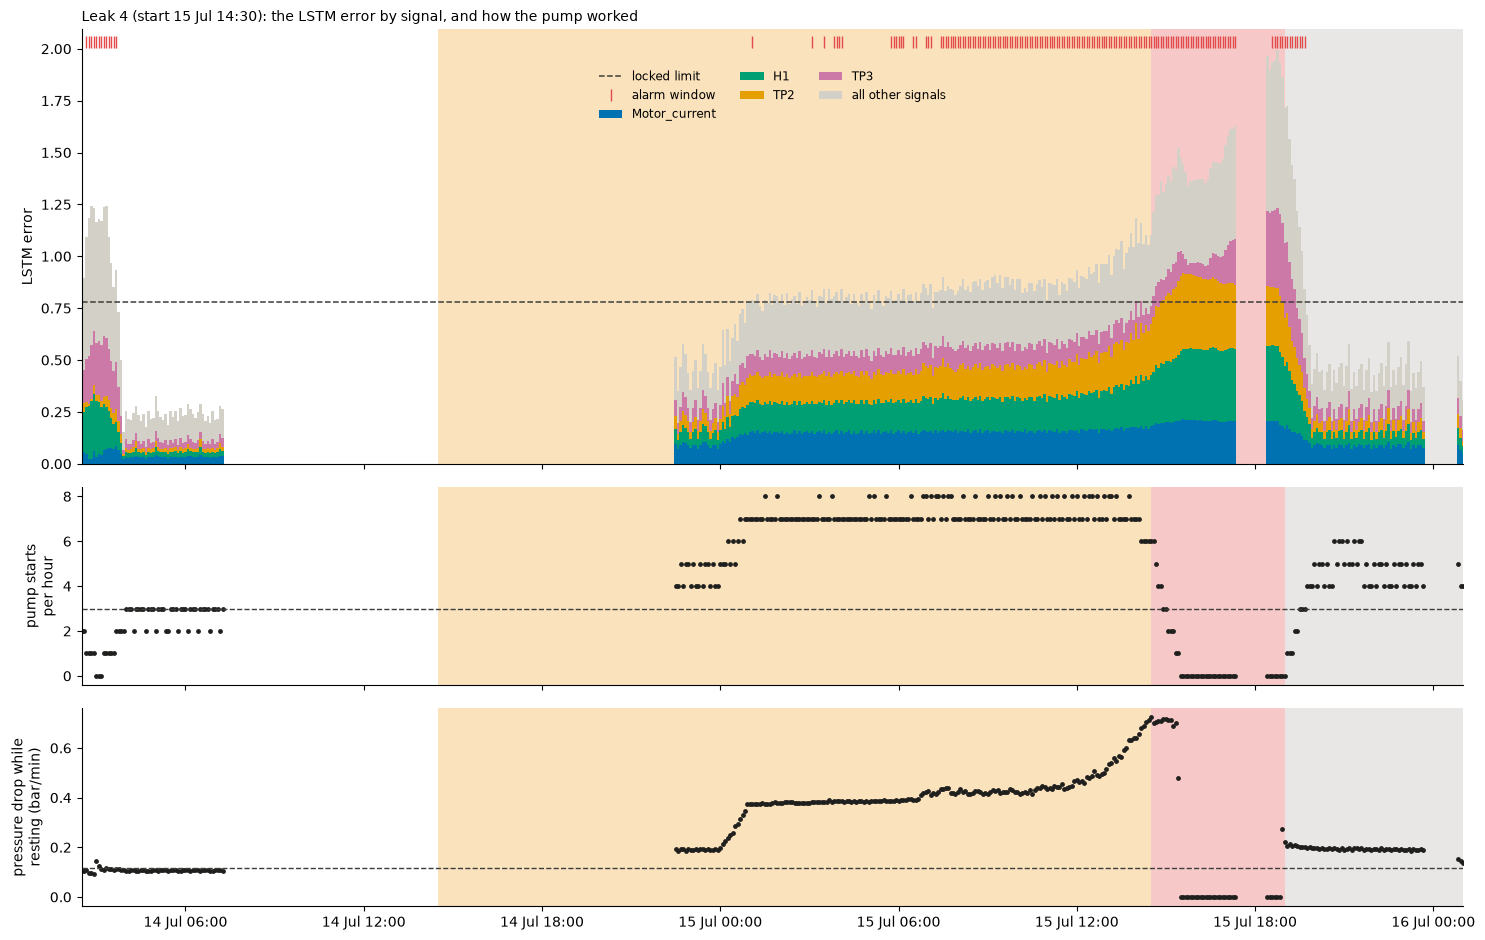

First LSTM alarm in the warning zone: 15 Jul 01:05 | signals in the chart: ['Motor_current', 'H1', 'TP2', 'TP3']


In [36]:
leak_4 = leaks[leaks["leak"] == 4].iloc[0]
view_from, view_to = leak_4["warning_from"] - pd.Timedelta(hours=HOURS_BEFORE_WARNING), leak_4["end"] + pd.Timedelta(hours=HOURS_AFTER_LEAK)
in_view = ((df_all["end"] >= view_from) & (df_all["end"] <= view_to)).to_numpy()
top_signals = lstm_shares.loc["Warning zone of leak 4"].sort_values(ascending=False).head(len(SIGNAL_COLORS)).index.tolist()
view = df_all[in_view]
width = STEP_MINUTES / (24 * 60)

fig, axes = plt.subplots(3, 1, figsize=(15, 9.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
for ax in axes:
    ax.axvspan(leak_4["warning_from"], leak_4["start"], color=ZONE_COLORS["warning"], alpha=0.3, linewidth=0)
    ax.axvspan(leak_4["start"], leak_4["end"], color=ZONE_COLORS["leak"], alpha=0.3, linewidth=0)
    ax.axvspan(leak_4["end"], view_to, color=ZONE_COLORS["ignored"], alpha=0.3, linewidth=0)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
bottom = np.zeros(len(view))
for signal, color in zip(top_signals, SIGNAL_COLORS):
    axes[0].bar(view["end"], lstm_parts.loc[in_view, signal], width=width, bottom=bottom, color=color, label=signal, linewidth=0)
    bottom += lstm_parts.loc[in_view, signal].to_numpy()
axes[0].bar(view["end"], view["lstm_autoencoder"].to_numpy() - bottom, width=width, bottom=bottom, color="#D3D1C7", label="all other signals", linewidth=0)
axes[0].axhline(LIMITS["lstm_autoencoder"], color="#3D3D3A", linestyle="--", linewidth=1.1, label="locked limit")
alarm_ends = view.loc[view["lstm_autoencoder_alarm"], "end"]
axes[0].plot(alarm_ends, np.full(len(alarm_ends), 0.97), linestyle="none", marker="|", markersize=9, color="#E24B4A", transform=axes[0].get_xaxis_transform(), label="alarm window")
axes[0].set_ylabel("LSTM error")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=8.5, ncol=3)
axes[1].scatter(view["end"], view["pump_starts"], s=6, color="#1F1F1E")
axes[1].axhline(df_all.loc[is_february, "pump_starts"].quantile(BUSY_QUANTILE), color="#3D3D3A", linestyle="--", linewidth=1)
axes[1].set_ylabel("pump starts\nper hour")
axes[2].scatter(view["end"], view["drop_bar_per_min"], s=6, color="#1F1F1E")
axes[2].axhline(df_all.loc[is_february, "drop_bar_per_min"].quantile(BUSY_QUANTILE), color="#3D3D3A", linestyle="--", linewidth=1)
axes[2].set_ylabel("pressure drop while\nresting (bar/min)")
axes[2].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
axes[2].set_xlim(view_from, view_to)
axes[0].set_title(f"Leak 4 (start {leak_4['start']:%d %b %H:%M}): the LSTM error by signal, and how the pump worked", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

first_warning = view.loc[view["lstm_autoencoder_alarm"] & (view["zone"] == "warning"), "end"].min()
print(f"First LSTM alarm in the warning zone: {first_warning:%d %b %H:%M} | signals in the chart: {top_signals}")

> **What we see:**
>
> - **Half a day before the warning zone**, the pump starts a few times per hour and the pressure drops slowly while it rests, close to February. Then the recording stops for many hours: no windows.
> - **When the recording comes back**, a few hours into the warning zone, the pressure already drops faster than in almost any February hour. Soon after, the drop speed jumps up again and the pump starts far more often. The LSTM error jumps with it, carried by the pump signals, and creeps over the limit: the early warning. At first it stays only just above the limit.
> - **Through the morning** the pressure drops faster and faster, and the error grows. At the start of the leak the pump stops resting altogether.
> - **After the leak**, in the ignored zone, the pressure still drops faster than in February, as if air was still escaping. This fits the reason for the ignored zone in notebook 1.2: the repair came later than the reported end.
>
> The forest saw the same hours (see "The Strongest Summary Numbers"), but its total push mostly stayed under what its limit needs.

## Every False Alarm

### The False Alarm Events

> Every false alarm event of both models, described with `describe_events()` (see Functions for the rule behind "looks like"). The top signals are those of the model that raised the event: for the LSTM, shares of its error; for the forest, shares of its push.

In [37]:
busy_limit = df_all.loc[is_february, f"{PUMP_COLUMN}_on_share"].quantile(BUSY_QUANTILE)
test_parts = {"lstm_autoencoder": lstm_parts[is_test].reset_index(drop=True), "isolation_forest": forest_parts[is_test].reset_index(drop=True)}
false_tables = []
for model, name in MODEL_NAMES.items():
    described = describe_events(events=false_events[model], alarms=df_test[f"{model}_alarm"].to_numpy(), counted=healthy, df_test=df_test,
                                parts=test_parts[model], busy_limit=busy_limit, top_signals=TOP_SIGNALS, pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN)
    false_tables.append(described.assign(model=name))
df_false = pd.concat(false_tables, ignore_index=True)

print(f"Pumped more than usual: the pump ran more than {busy_limit:.0%} of the hour (the {BUSY_QUANTILE:.0%} quantile of February)")
shown = df_false.assign(first_alarm=df_false["first_alarm"].dt.strftime("%d %b %H:%M"), last_alarm=df_false["last_alarm"].dt.strftime("%d %b %H:%M"))
display(shown.set_index(["model", "first_alarm"]).drop(columns=["tanks_below_7_bar"]).style.format({"pump_never_rested": "{:.0%}", "pumping_share": "{:.0%}", "lowest_tank_bar": "{:.1f}"}))

Pumped more than usual: the pump ran more than 11% of the hour (the 99% quantile of February)


### Four Kinds of False Alarms

> How many false alarm events of each kind every model raised, and how many alarm windows they hold.

In [38]:
kinds = df_false.groupby(["looks_like", "model"]).agg(events=("alarm_windows", "size"), alarm_windows=("alarm_windows", "sum")).unstack("model")
kinds = kinds.reindex(KIND_ORDER).fillna(0).astype(int)
kinds = kinds.loc[kinds.sum(axis=1) > 0]
display(kinds)

events                     alarm_windows  \
model                  Isolation Forest LSTM autoencoder Isolation Forest   
looks_like                                                                  
pump never rested                     6                3              171   
tanks below 7 bar                     2                5                3   
pumped more than usual                0               12                0   
frozen readings                       0                1                0   

                                         
model                  LSTM autoencoder  
looks_like                               
pump never rested                   533  
tanks below 7 bar                    49  
pumped more than usual              134  
frozen readings                     737

> **What we see:**
>
> - **Pump never rested:** the largest events of the LSTM, and most events of the forest. In these hours the pump ran nonstop, the tanks stayed below the pressure at which the pump stops, and `DV_pressure` sat above zero: exactly what the reported leaks look like. The forest's events of this kind are the same hours as the LSTM's: the hours with the lowest tank pressure among them.
> - **Tanks below 7 bar:** short events in which the tank pressure fell below 7 bar, so `LPS` switched on. In February `LPS` never switched on (notebook 3.2).
> - **Pumped more than usual:** many short LSTM events with long pump runs, often with `DV_pressure` up, but with rests in between. The forest raised none of them.
> - **Frozen readings:** one long LSTM event, the stretch of notebook 5.2.
>
> The dataset reports no failure in any of these hours, so they count as false alarms, and they stay false alarms in this project: the results of notebook 5.2 do not change. But the hours in which the pump never rested look just like the reported leaks. They may have been air losses that nobody reported, like the unusual March hours of notebook 3.2. Notebook 5.4 and the README come back to this.

### One Hour of Each Kind

> For every kind, the largest false alarm event, and in it the middle alarm window by its score: the tank pressure and `DV_pressure`, as in "Three Hours Up Close".

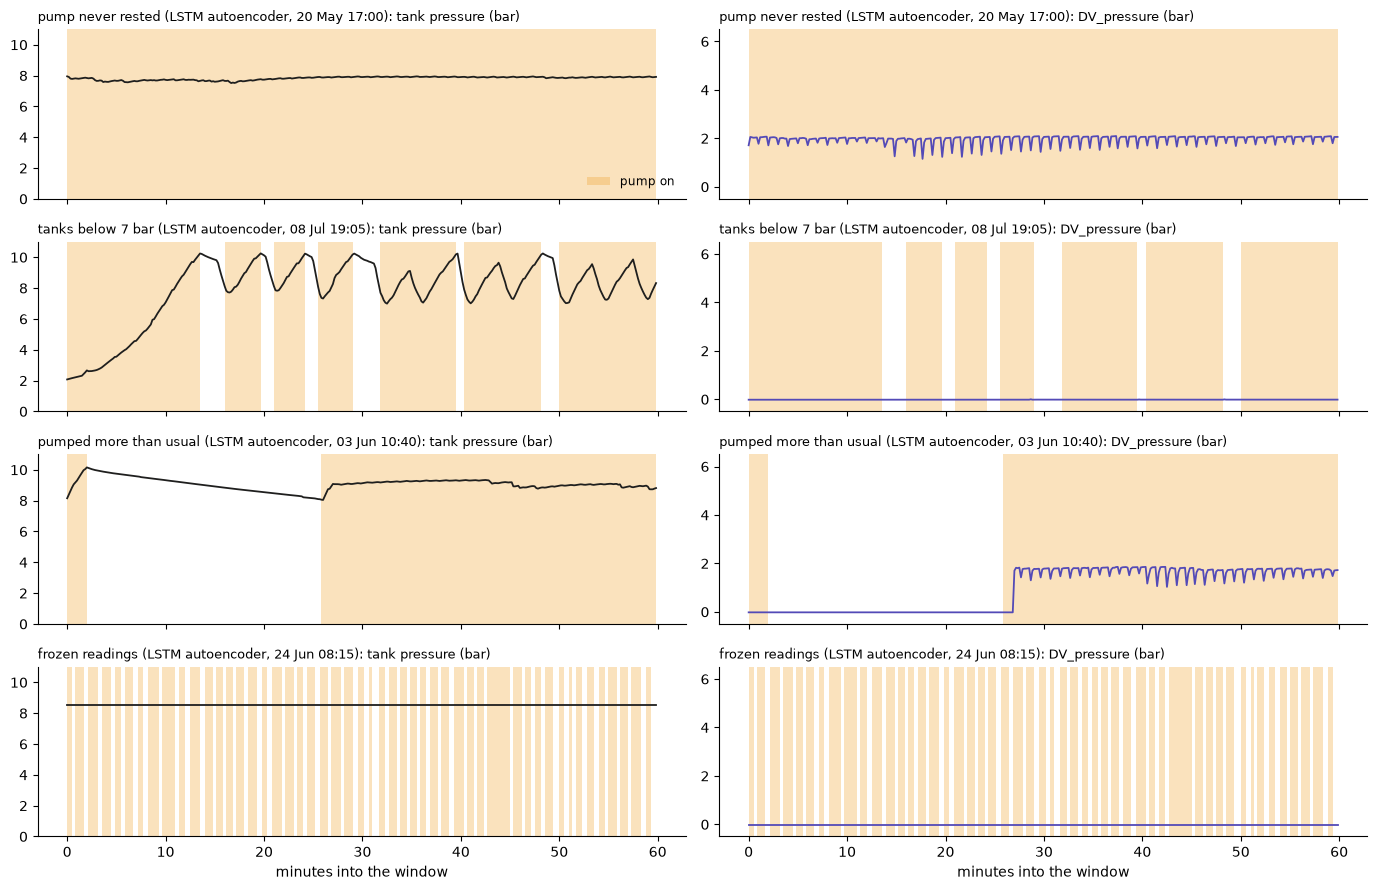

In [39]:
kind_examples = {}
for kind in [kind for kind in KIND_ORDER if kind in set(df_false["looks_like"])]:
    event = df_false[df_false["looks_like"] == kind].sort_values("alarm_windows", ascending=False).iloc[0]
    model = next(model for model, name in MODEL_NAMES.items() if name == event["model"])
    inside = (df_test[f"{model}_alarm"] & healthy & (df_test["end"] >= event["first_alarm"]) & (df_test["end"] <= event["last_alarm"])).to_numpy()
    position = middle_window(values=df_test[model].to_numpy(), mask=inside)
    kind_examples[f"{kind} ({event['model']}, {df_test.loc[position, 'end']:%d %b %H:%M})"] = int(df_test.loc[position, "end_index"])
hours = hours_in_real_units(grid_values=grid_values, grid_signals=grid_signals, scaled_columns=scaled_columns, scale_mean=scale_mean, scale_std=scale_std,
                            end_indices=list(kind_examples.values()), window_steps=WINDOW_STEPS, columns=[TANK_COLUMN, PUMP_COLUMN, DRYER_COLUMN])
draw_hours(titles=list(kind_examples), hours=hours, pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN, dryer_column=DRYER_COLUMN, minutes=minutes,
           pump_color=ZONE_COLORS["warning"])

> **What we see:**
>
> - **Pump never rested:** the same picture as during leak 3: the pump runs the whole hour, the tank pressure is flat, `DV_pressure` is high.
> - **Tanks below 7 bar:** the hour starts with nearly empty tanks, a long pump run fills them up from far below the normal range, and then the pressure keeps falling fast between short pump runs.
> - **Pumped more than usual:** a long pump run in which the tank pressure never reaches the level at which the pump stops, and `DV_pressure` is up: like a short piece of a leak hour.
> - **Frozen readings:** the pressures are flat lines, while the on/off pump signal still flickers. The analog values are stuck, so this hour shows nothing real about the pressures.

## Save

### What Will Be Written

> `results/alarm_events.csv`: every alarm event of the test months for both models, described with `describe_events()`. Besides the false alarms, the alarms around each leak are grouped into events too: those in the warning zone and during the leak (`leak`), and those in the ignored zone (`ignored zone`), with the same 60-minute merge. The check makes sure that the events hold every alarm window of notebook 5.2, and each only once.

In [40]:
event_tables = []
for model, name in MODEL_NAMES.items():
    alarms = df_test[f"{model}_alarm"].to_numpy()
    counted_sets = [("false alarm", 0, healthy)]
    for number in leaks["leak"]:
        counted_sets.append(("leak", number, ((df_test["leak"] == number) & df_test["zone"].isin(["warning", "leak"])).to_numpy()))
        counted_sets.append(("ignored zone", number, ((df_test["leak"] == number) & (df_test["zone"] == "ignored")).to_numpy()))
    for kind, number, counted in counted_sets:
        if not (alarms & counted).any():
            continue
        events = find_events(alarms=alarms, counted=counted, ends=df_test["end"], merge_gap_minutes=MERGE_GAP_MINUTES)
        described = describe_events(events=events, alarms=alarms, counted=counted, df_test=df_test, parts=test_parts[model], busy_limit=busy_limit,
                                    top_signals=TOP_SIGNALS, pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN)
        described.insert(0, "leak", number)
        described.insert(0, "kind", kind)
        described.insert(0, "model", name)
        event_tables.append(described)
df_events = pd.concat(event_tables, ignore_index=True)

windows_in_events = df_events.groupby("model")["alarm_windows"].sum()
windows_in_5_2 = pd.Series({name: int(df_test[f"{model}_alarm"].sum()) for model, name in MODEL_NAMES.items()})
print(f"alarm_events: {df_events.shape[0]} rows x {df_events.shape[1]} columns")
display(pd.DataFrame({"alarm windows in the events": windows_in_events, "alarm windows of notebook 5.2": windows_in_5_2}))
display(df_events.groupby(["model", "kind"]).size().unstack(fill_value=0))
display(df_events.head(3))
check("the events hold every test alarm window of notebook 5.2", windows_in_events.equals(windows_in_5_2.reindex(windows_in_events.index))
      and (df_events["kind"] == "false alarm").groupby(df_events["model"]).sum().to_dict() == {name: len(false_events[model]) for model, name in MODEL_NAMES.items()})
print(f"{os.path.relpath(EVENTS_FILE, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(EVENTS_FILE) else 'new file'}")

alarm_events: 46 rows x 13 columns


,alarm windows in the events,alarm windows of notebook 5.2
Isolation Forest,221,221
LSTM autoencoder,2533,2533


kind,false alarm,ignored zone,leak
model,,,
Isolation Forest,8,1,3
LSTM autoencoder,21,4,9


,model,kind,leak,first_alarm,last_alarm,alarm_windows,frozen_windows,pump_never_rested,pumping_share,lowest_tank_bar,tanks_below_7_bar,looks_like,top_signals
0,Isolation Forest,false alarm,0,2020-04-06 15:20:00,2020-04-06 15:20:00,1,0,0.0,0.252778,6.006,True,tanks below 7 bar,"TP3 12%, H1 11%, Reservoirs 10%"
1,Isolation Forest,false alarm,0,2020-05-13 15:15:00,2020-05-13 18:30:00,40,0,1.0,1.000000,7.178,False,pump never rested,"TP3 14%, Reservoirs 13%, DV_pressure 11%"
2,Isolation Forest,false alarm,0,2020-05-13 20:00:00,2020-05-14 00:55:00,57,0,1.0,1.000000,7.124,False,pump never rested,"TP3 14%, Reservoirs 13%, DV_pressure 11%"


PASS  the events hold every test alarm window of notebook 5.2
results\alarm_events.csv: new file


### Save the Events

In [41]:
os.makedirs(RESULTS_DIR, exist_ok=True)
df_events.to_csv(EVENTS_FILE, index=False)
print(f"Saved {os.path.relpath(EVENTS_FILE, ROOT_DIR)} ({os.path.getsize(EVENTS_FILE) / 1024:,.0f} KB)")

Saved results\alarm_events.csv (7 KB)


### Read the File Back

In [42]:
events_back = pd.read_csv(EVENTS_FILE, parse_dates=["first_alarm", "last_alarm"])
same = events_back.shape == df_events.shape and list(events_back.columns) == list(df_events.columns)
for column in df_events.columns:
    if same and pd.api.types.is_float_dtype(df_events[column]):
        same = np.allclose(events_back[column].to_numpy(dtype="float64"), df_events[column].to_numpy(dtype="float64"), equal_nan=True)
    elif same:
        same = (events_back[column].astype(str) == df_events[column].astype(str)).all()
check("the saved events read back the same", same)

PASS  the saved events read back the same


## Result

### Final Result

> If every check passed, the alarms explained here are exactly those of notebook 5.2, the splits into signals add up, and the events are saved. If a check failed, its name is printed.

In [43]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (10 checks)


## Summary

> - **Why the LSTM rang during the leaks:** the pump ran nonstop for hours. During leaks 1 to 3 `DV_pressure` was up all that time, which never happened in February, so the LSTM redraws it badly: about half of its error comes from `DV_pressure`, much of the rest from the pump signals `H1`, `TP2` and `Motor_current`. During leak 4 the pump signals alone carried the error.
> - **Why the forest mostly stayed quiet:** it noticed the same hours, with pushes from many summary numbers at once, but its total push stops just under what its limit needs: the ceiling of notebook 4.1.
> - **Why leak 4 was the only early warning:** before leak 4 the tank pressure dropped several times faster while the pump rested, so the pump started far more often. The LSTM saw this in the pump signals. Before leaks 1 to 3 the compressor behaved like on a healthy day, so there was nothing to see before they started.
> - **What the false alarms are:** hours in which the pump never rested (the largest events, and most events of the forest), moments with the tanks below 7 bar, hours with more pumping than usual, and one stretch of frozen readings. The hours in which the pump never rested look just like the reported leaks, so some "false" alarms may be air losses that were never reported.
> - Every alarm event is saved in `results/alarm_events.csv`, with what the compressor did and its top signals.
>
> **Next:** `notebooks/5_evaluation/5.4_tradeoff_and_speed.ipynb`